# 16 · Explaining the Detector (SHAP and LIME)

**The question:** *Why* does the final detector raise a given alert, and can we trust those explanations?

| | |
|---|---|
| **Input** | The final detector chosen in Notebook 15; `model_selection` rows |
| **What we do** | Explain predictions with SHAP and LIME, in terms of the 42 original measured columns, and **test** whether the explanations are faithful |
| **Output** | Global and per-class importance, example alert explanations, and a faithfulness test. Notebook 18 uses these explanations in incident reports |

### Two explanation methods in plain words

- **SHAP** asks: "starting from an average flow, how much does each column push the probability of this class up or down?" The pushes add up exactly to
  the difference between this flow's probability and the average probability.
- **LIME** asks: "if I change this flow a little in many random ways, which columns does a simple straight-line model need to imitate the detector nearby?"

Explanations can be wrong. So we also run a **faithfulness test**: if the columns SHAP calls most important are replaced by neutral values, the
prediction should change much more than when random columns are replaced.

## 1. Setup and the final detector

In [1]:
import sys
import time
import warnings
from pathlib import Path
sys.path.insert(0, str(next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'src').is_dir())))
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from lime.lime_tabular import LimeTabularExplainer

from src.notebook_helpers import TRAIN_CSV, RAW_SHA256, CLASSES, CATEGORICAL, DATA, MODELS, sha256, save_table, save_figure, save_json, setup_style
from src.final_detector import FinalDetector, load_raw
from src.explain import RawSpace, make_predict_fn, shap_values, top_features
from src.flow_networks import show_code
setup_style()
assert sha256(TRAIN_CSV) == RAW_SHA256['train']

detector = FinalDetector.load()
print('Final detector (Notebook 15):', detector.name)
train_raw, eval_raw = load_raw('train'), load_raw('model_selection')
y_eval = pd.Categorical(eval_raw.attack_cat, categories=CLASSES).codes

Final detector (Notebook 15): LightGBM (sqrt)


**Check first:** the detector, fed with *raw* rows through the frozen preprocessing, must give exactly the probabilities saved earlier
for the `model_selection` rows. Otherwise we would be explaining a different model.

In [2]:
proba = detector.predict_proba(eval_raw, calibrated=False)
saved = {'lightgbm': DATA / f"10_lightgbm_{detector.spec['lightgbm_treatment']}_proba.csv"}
if detector.kind == 'lightgbm':
    reference = pd.read_csv(saved['lightgbm']).to_numpy()
else:
    network = np.mean([pd.read_csv(DATA / f'14_proposed_seed{s}_proba.csv')[[f'p_{c}' for c in CLASSES]].to_numpy() for s in (42, 43, 44)], axis=0)
    reference = network if detector.kind == 'proposed' else (pd.read_csv(saved['lightgbm']).to_numpy() + network) / 2
print('largest difference from the saved probabilities:', float(np.abs(proba - reference).max()))
print('same predicted class for every row:', bool((proba.argmax(1) == reference.argmax(1)).all()))
assert (proba.argmax(1) == reference.argmax(1)).all()

largest difference from the saved probabilities: 1.1102230246251565e-16
same predicted class for every row: True


## 2. Which rows we explain

Exact SHAP for every row would take hours, so we explain a **stratified sample**: 20 rows of every class (all 13 Worms rows), 193 rows in total,
against a **background** of 50 random train rows that defines "an average flow". The code of the explanation helpers:

In [3]:
show_code(RawSpace, shap_values)
predictors = [c for c in train_raw.columns if c not in ['id', 'label', 'attack_cat']]
space = RawSpace(train_raw, predictors)
rng = np.random.default_rng(0)
sample_idx = np.concatenate([rng.choice(np.flatnonzero(y_eval == k), min(20, (y_eval == k).sum()), replace=False) for k in range(10)])
background = space.encode(train_raw.sample(50, random_state=0))
rows = space.encode(eval_raw.iloc[sample_idx])
print(f'explaining {len(sample_idx)} rows with {len(predictors)} columns')

```python
class RawSpace:
    """Converts between raw flow rows and the numeric matrix used by the explainers."""

    def __init__(self, train_frame, predictors):
        self.predictors = list(predictors)
        self.cat_index = [self.predictors.index(c) for c in CATEGORICAL]
        self.vocab = {c: sorted(train_frame[c].astype(str).unique()) for c in CATEGORICAL}
        self.reference = {c: (train_frame[c].mode().iloc[0] if c in CATEGORICAL else float(train_frame[c].median()))
                          for c in self.predictors}

    def encode(self, frame):
        x = frame[self.predictors].copy()
        for c in CATEGORICAL:
            lookup = {v: i for i, v in enumerate(self.vocab[c])}
            x[c] = x[c].astype(str).map(lambda v: lookup.get(v, -1))
        return x.to_numpy(dtype=float)

    def decode(self, x):
        frame = pd.DataFrame(np.asarray(x, dtype=float), columns=self.predictors)
        for c in CATEGORICAL:
            codes = np.clip(np.rint(frame[c].to_numpy()).astype(int), -1, len(self.vocab[c]) - 1)
            frame[c] = [self.vocab[c][k] if k >= 0 else '__unseen__' for k in codes]
        for c in self.predictors:
            if c not in CATEGORICAL:
                frame[c] = frame[c].astype(float)
        return frame

```

```python
def shap_values(detector, space, rows_encoded, background_encoded, seed=0):
    """Permutation SHAP values: array (rows, 42 features, 10 classes), in probability units."""
    f = make_predict_fn(detector, space)
    masker = shap.maskers.Independent(background_encoded, max_samples=len(background_encoded))
    explainer = shap.PermutationExplainer(f, masker, seed=seed)
    result = explainer(rows_encoded, max_evals=2 * len(space.predictors) + 1, silent=True)
    return result.values, result.base_values

```

explaining 193 rows with 42 columns


## 3. SHAP values

In [4]:
start = time.time()
values, base = shap_values(detector, space, rows, background)
print(f'SHAP shape {values.shape} (rows, columns, classes), {time.time() - start:.0f} s')
predicted = proba[sample_idx].argmax(1)
# The pushes must add up: base value + sum of SHAP values = the detector's probability (a correctness check of the method).
f = make_predict_fn(detector, space)
reconstructed = base + values.sum(axis=1)
print('largest additivity error:', float(np.abs(reconstructed - f(rows)).max()))
np.savez_compressed(DATA / '16_shap_values.npz', values=values, base=base, rows=sample_idx, predicted=predicted)

SHAP shape (193, 42, 10) (rows, columns, classes), 30 s
largest additivity error: 1.5543122344752192e-15


## 4. Global importance: which columns matter most overall?

Mean absolute SHAP value of each column for the **predicted** class of each row.

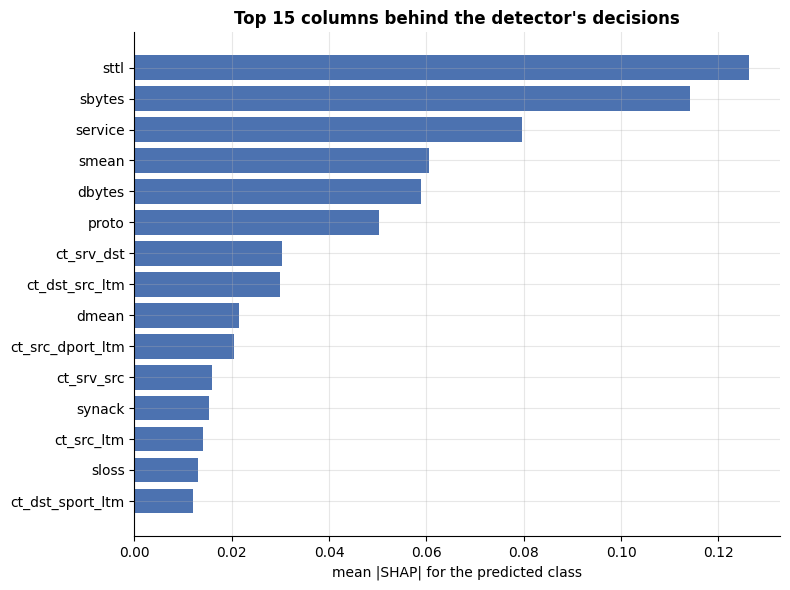

In [5]:
contrib_pred = values[np.arange(len(predicted)), :, predicted]               # (rows, columns)
global_importance = pd.Series(np.abs(contrib_pred).mean(0), index=predictors).sort_values(ascending=False)
save_table(global_importance.rename('mean |SHAP| (probability units)').to_frame(), '16_global_importance', index=True)

fig, ax = plt.subplots(figsize=(8, 6))
top = global_importance.head(15)[::-1]
ax.barh(top.index, top.values, color='#4C72B0')
ax.set(xlabel='mean |SHAP| for the predicted class', title='Top 15 columns behind the detector\'s decisions')
plt.tight_layout(); save_figure(fig, '16_global_importance'); plt.show()

**What we see:**

- The detector's decisions rest mainly on **`sttl`** (time-to-live) and **`sbytes`** (bytes sent), followed by `service`, `smean` (average packet size),
  `dbytes` (bytes received) and `proto`.
- This matches Notebooks 03 and 06: TTL, sizes and the type of connection carry most of the class information. The top column, `sttl`, is the one we
  flagged as possibly **testbed-specific** (it reflects the machines used to create the dataset).

## 5. Per class: what drives each attack type?

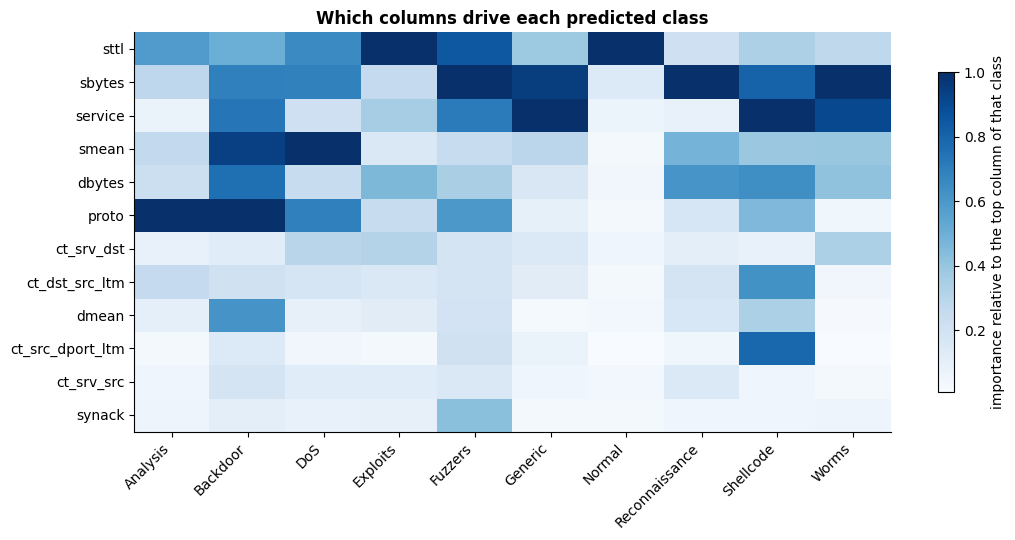

,top 3 columns
Analysis,"ct_flw_http_mthd, response_body_len, proto"
Backdoor,"ct_src_ltm, proto, smean"
DoS,"smean, proto, sbytes"
Exploits,"sttl, dbytes, service"
Fuzzers,"sbytes, sttl, service"
Generic,"service, sbytes, sttl"
Normal,"sttl, sbytes, service"
Reconnaissance,"sbytes, dbytes, smean"
Shellcode,"service, sbytes, ct_src_dport_ltm"
Worms,"sbytes, service, dbytes"


In [6]:
per_class = pd.DataFrame({CLASSES[k]: np.abs(values[predicted == k][:, :, k]).mean(0) if (predicted == k).any() else np.nan
                          for k in range(10)}, index=predictors)
top_columns = global_importance.head(12).index
fig, ax = plt.subplots(figsize=(11, 5.5))
heat = per_class.loc[top_columns]
im = ax.imshow(heat / heat.max(axis=0), cmap='Blues', aspect='auto')
ax.set_xticks(range(10), CLASSES, rotation=45, ha='right'); ax.set_yticks(range(len(top_columns)), top_columns); ax.grid(False)
fig.colorbar(im, ax=ax, shrink=0.8, label='importance relative to the top column of that class')
ax.set_title('Which columns drive each predicted class')
plt.tight_layout(); save_figure(fig, '16_per_class_importance'); plt.show()
save_table(per_class, '16_per_class_importance', index=True)
display(per_class.apply(lambda s: ', '.join(s.sort_values(ascending=False).head(3).index)).rename('top 3 columns').to_frame())

**What we see:** each class has its own fingerprint:

- **Analysis** is driven by HTTP-related columns (`ct_flw_http_mthd`, `response_body_len`) and the protocol;
- **DoS**, **Reconnaissance** and **Worms** mainly by flow sizes (`smean`, `sbytes`, `dbytes`);
- **Generic** and **Shellcode** by the `service` column; **Exploits**, **Fuzzers** and **Normal** by `sttl` together with sizes and service.

These are plausible network signatures (scans and floods are about size and rate; service-based attacks about the service), which makes the
explanations useful for an analyst.

## 6. Two alerts explained

Two correctly detected attacks (the first DoS and the first Exploits row of the sample). Bars to the right push the predicted class up,
bars to the left push it down. For example, the DoS flow is recognised by its small fixed size (`sbytes` = 200, `smean` = 100), TTL 254 and
protocol `gre`; the Exploits flow mainly by its service (`ftp`).

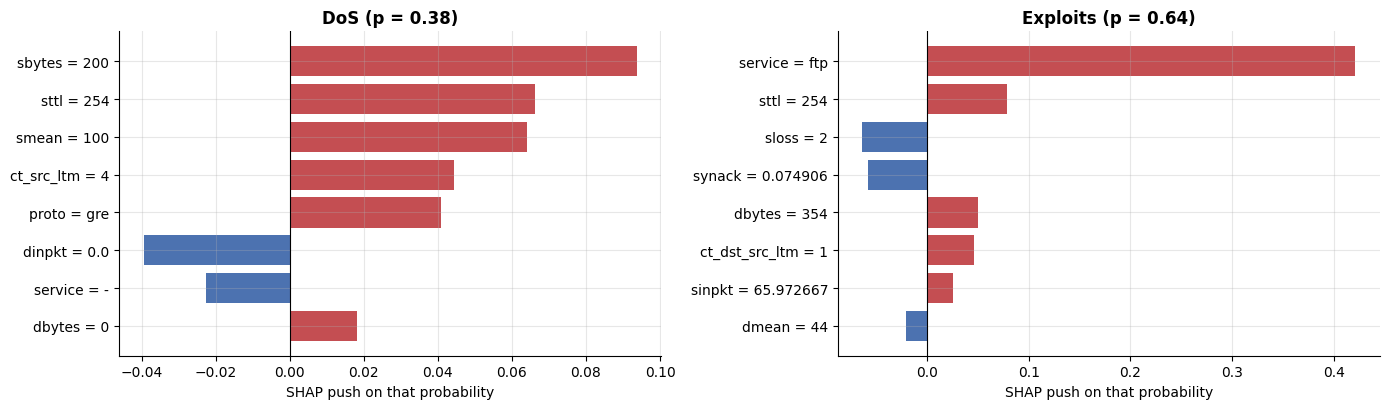

In [7]:
examples = []
for wanted in ['DoS', 'Exploits', 'Reconnaissance', 'Normal']:
    k = CLASSES.index(wanted)
    hits = np.flatnonzero((y_eval[sample_idx] == k) & (predicted == k))
    if len(hits):
        examples.append(hits[0])
examples = examples[:2]
fig, axes = plt.subplots(1, len(examples), figsize=(7 * len(examples), 4.2))
for ax, i in zip(np.atleast_1d(axes), examples):
    feats = top_features(values[i], predicted[i], predictors, k=8)[::-1]
    raw_row = eval_raw.iloc[sample_idx[i]]
    labels = [f'{n} = {raw_row[n]}' for n, _ in feats]
    ax.barh(labels, [v for _, v in feats], color=['#C44E52' if v > 0 else '#4C72B0' for _, v in feats])
    ax.axvline(0, color='black', lw=0.8)
    ax.set(title=f'{CLASSES[predicted[i]]} (p = {proba[sample_idx[i], predicted[i]]:.2f})', xlabel='SHAP push on that probability')
plt.tight_layout(); save_figure(fig, '16_example_alerts'); plt.show()

## 7. LIME, and does it agree with SHAP?

LIME explains each row separately with a local straight-line model. For 50 rows (5 per class) we compare LIME's top-5 columns with SHAP's top-5.
Agreement = share of the 5 columns that both methods name.

In [8]:
lime_explainer = LimeTabularExplainer(space.encode(train_raw.sample(5000, random_state=0)), feature_names=predictors,
                                      categorical_features=space.cat_index, class_names=CLASSES, discretize_continuous=True,
                                      mode='classification', random_state=0)
predict_fn = make_predict_fn(detector, space)
agreement = []
lime_rows = np.concatenate([np.flatnonzero(y_eval[sample_idx] == k)[:5] for k in range(10)])
start = time.time()
for i in lime_rows:
    exp = lime_explainer.explain_instance(rows[i], predict_fn, labels=[predicted[i]], num_features=5, num_samples=1000)
    lime_top = {predictors[j] for j, _ in exp.as_map()[predicted[i]]}
    shap_top = {n for n, _ in top_features(values[i], predicted[i], predictors, k=5)}
    agreement.append({'row': int(sample_idx[i]), 'true class': CLASSES[y_eval[sample_idx[i]]], 'predicted': CLASSES[predicted[i]],
                      'shared top-5 columns': len(lime_top & shap_top), 'agreement': len(lime_top & shap_top) / 5})
agreement = pd.DataFrame(agreement)
save_table(agreement, '16_lime_shap_agreement')
print(f'LIME on {len(lime_rows)} rows: {time.time() - start:.0f} s')
display(agreement.groupby('predicted')['agreement'].mean().rename('mean agreement (share of top-5 shared)').to_frame().T)
print(f"overall agreement: {agreement['agreement'].mean():.2f} | random chance for 5 of 42 columns: {5 / 42:.2f}")

LIME on 50 rows: 17 s


predicted,Analysis,DoS,Exploits,Fuzzers,Generic,Normal,Reconnaissance,Shellcode,Worms
mean agreement (share of top-5 shared),0.4000,0.4444,0.5000,0.5714,0.7200,0.4500,0.3200,0.6000,0.4000


overall agreement: 0.50 | random chance for 5 of 42 columns: 0.12


**What we see:**

- On average **half of the top-5 columns are the same** for LIME and SHAP (0.50), four times more than chance (0.12).
- Agreement is highest for Generic (0.72) and Shellcode (0.60), lowest for Reconnaissance (0.32). The two methods ask different questions (global
  average versus local imitation), so partial agreement is expected; the columns they share are the most trustworthy part of an explanation.

## 8. Faithfulness test: do the "important" columns really drive the prediction?

For every explained row we replace its top-k SHAP columns with neutral values (the train median for numbers, the most common value for text) and
measure how much the probability of the predicted class drops. As a control we replace k **random** columns instead (average of 5 draws).

,columns replaced (k),"mean drop, SHAP top-k","mean drop, random k",ratio
0,1,0.3330,0.0190,17.4926
1,3,0.4871,0.0567,8.5852
2,5,0.5484,0.1018,5.3864
3,10,0.6068,0.1983,3.0598


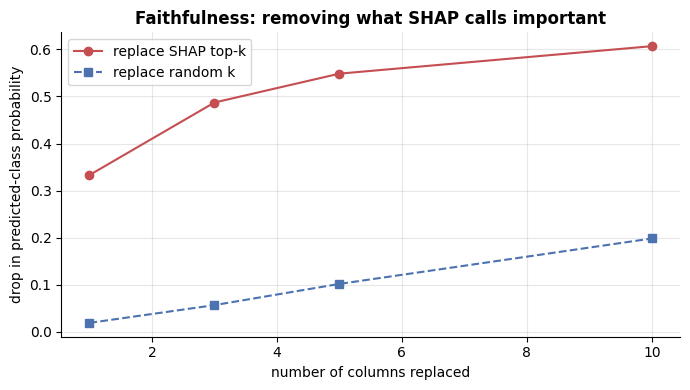

In [9]:
reference_row = np.array([space.reference[c] if c not in CATEGORICAL else space.vocab[c].index(str(space.reference[c])) for c in predictors], dtype=float)
p_before = predict_fn(rows)[np.arange(len(rows)), predicted]
faith = []
for k in (1, 3, 5, 10):
    shap_x, random_drops = rows.copy(), []
    for i in range(len(rows)):
        order = np.argsort(-np.abs(values[i, :, predicted[i]]))[:k]
        shap_x[i, order] = reference_row[order]
    shap_drop = p_before - predict_fn(shap_x)[np.arange(len(rows)), predicted]
    for draw in range(5):
        rand_x = rows.copy()
        for i in range(len(rows)):
            pick = rng.choice(len(predictors), k, replace=False)
            rand_x[i, pick] = reference_row[pick]
        random_drops.append(p_before - predict_fn(rand_x)[np.arange(len(rows)), predicted])
    faith.append({'columns replaced (k)': k, 'mean drop, SHAP top-k': shap_drop.mean(), 'mean drop, random k': np.mean(random_drops),
                  'ratio': shap_drop.mean() / max(np.mean(random_drops), 1e-9)})
faith = pd.DataFrame(faith)
save_table(faith, '16_faithfulness')
display(faith)

fig, ax = plt.subplots(figsize=(7, 4))
ax.plot(faith['columns replaced (k)'], faith['mean drop, SHAP top-k'], 'o-', label='replace SHAP top-k', color='#C44E52')
ax.plot(faith['columns replaced (k)'], faith['mean drop, random k'], 's--', label='replace random k', color='#4C72B0')
ax.set(xlabel='number of columns replaced', ylabel='drop in predicted-class probability', title='Faithfulness: removing what SHAP calls important')
ax.legend(); plt.tight_layout(); save_figure(fig, '16_faithfulness'); plt.show()

**What we see:**

- **The SHAP explanations are faithful.** Replacing the single most important column lowers the predicted-class probability by **0.33** on average;
  replacing one random column lowers it by only **0.02** (17 times less).
- The gap stays large for 3, 5 and 10 columns (ratios 8.6, 5.4 and 3.1). So the columns SHAP names really drive the detector's decisions, which is what
  Notebook 18 relies on when it cites them in incident reports.

## 9. Save

In [10]:
save_json({'detector': detector.name, 'explained_rows': int(len(sample_idx)), 'background_rows': 50, 'method': 'shap.PermutationExplainer, 85 evaluations per row',
           'lime_rows': int(len(lime_rows)), 'overall_lime_shap_agreement': float(agreement['agreement'].mean())}, MODELS / '16_explanations.json')
assert sha256(TRAIN_CSV) == RAW_SHA256['train']
print('Saved SHAP values, importance tables, agreement and faithfulness results.')

Saved SHAP values, importance tables, agreement and faithfulness results.


## Summary

### What we learned

| Question | Answer |
|---|---|
| Do we explain the right model? | Yes: the raw-input detector reproduces the saved predictions exactly (difference 1e-16) |
| Are the SHAP values exact? | Yes: the pushes add up to the detector's probability (error 1.6e-15) |
| What drives the decisions? | Mainly `sttl`, `sbytes`, `service`, `smean`, `dbytes`, `proto` |
| Does each class have its own drivers? | Yes: HTTP columns for Analysis, sizes for DoS / Reconnaissance / Worms, service for Generic / Shellcode |
| Do LIME and SHAP agree? | Partly: half of the top-5 columns are shared (chance: 12%) |
| Are the explanations faithful? | **Yes**: removing SHAP's top column drops the probability 17× more than removing a random column |

### What is still uncertain

- The strongest driver, `sttl`, may be specific to the UNSW testbed; a detector deployed elsewhere should be checked for this dependence.
- Explanations show what the model *uses*, not what *causes* an attack.

### What comes next

**Notebook 17** makes the detector's confidence trustworthy (calibration) and adds prediction sets that can say "X or Y" when the data is ambiguous.